In [135]:
# House Price Prediction

 #Project Objective
The objective of this project is to predict house prices using Machine Learning algorithms based on different housing features.

## Problem Type
Supervised Machine Learning - Regression

In [136]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [137]:
df = pd.read_csv('data/housing.csv')


In [138]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [139]:
df.shape

(20640, 10)

In [140]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [141]:
df.duplicated().sum()

np.int64(0)

In [142]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [143]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


 # EDA - Exploratory Data Analysis

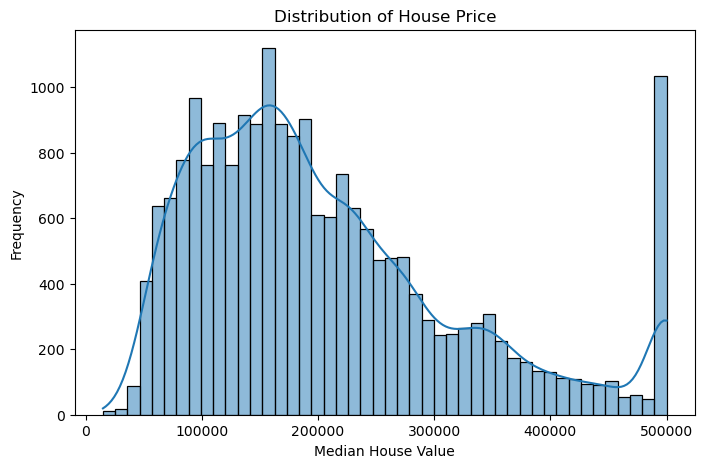

In [144]:
# Histogram of House Prices

plt.figure(figsize = (8,5))

sns.histplot(df['median_house_value'],kde = True)
plt.title('Distribution of House Price')
plt.xlabel('Median House Value')
plt.ylabel('Frequency')

plt.show()

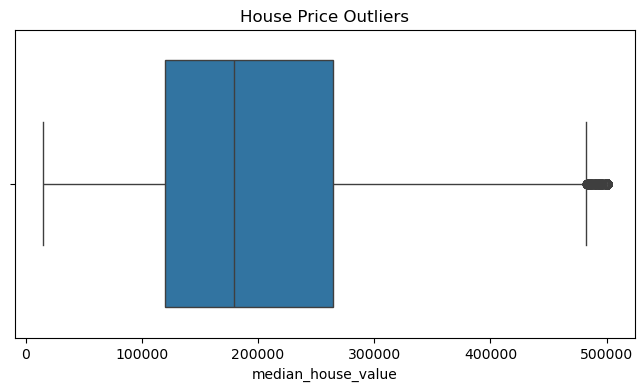

In [145]:
# Box Plot of House Prices

plt.figure(figsize =(8,4))
sns.boxplot( x = df['median_house_value'])
plt.title('House Price Outliers')

plt.show()

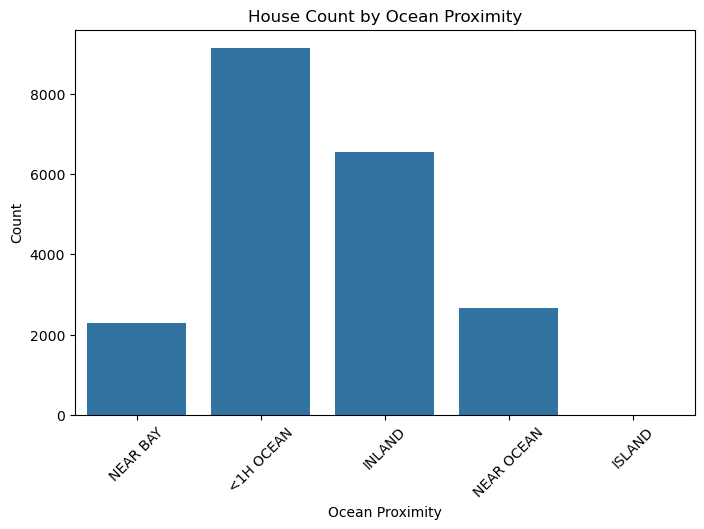

In [146]:
# Categorical Analysis

plt.figure(figsize=(8,5))

sns.countplot(data=df, x='ocean_proximity')

plt.title('House Count by Ocean Proximity')
plt.xlabel('Ocean Proximity')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

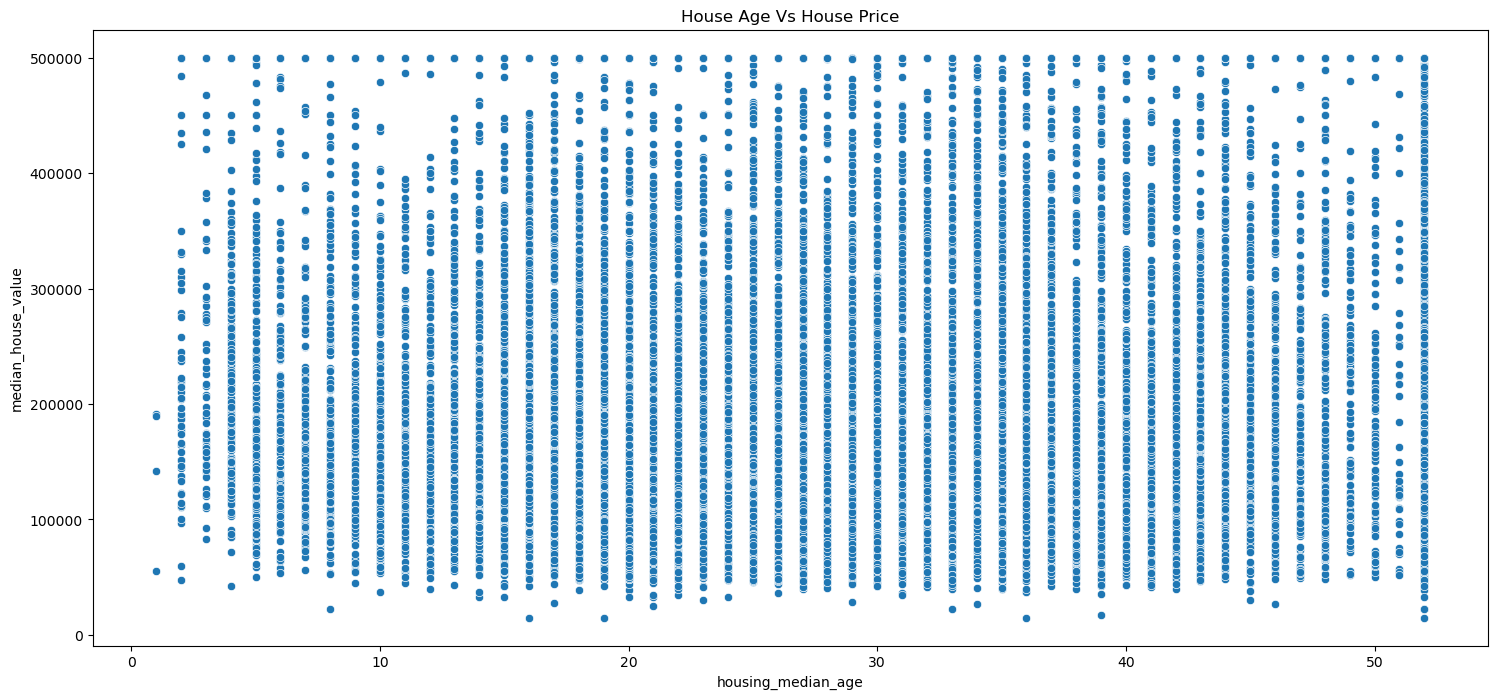

In [147]:
# Relationship between Features and Target

plt.figure(figsize= (18,8))

sns.scatterplot(data=df,
                x='housing_median_age',
                y='median_house_value'
)

plt.title('House Age Vs House Price')
plt.show()

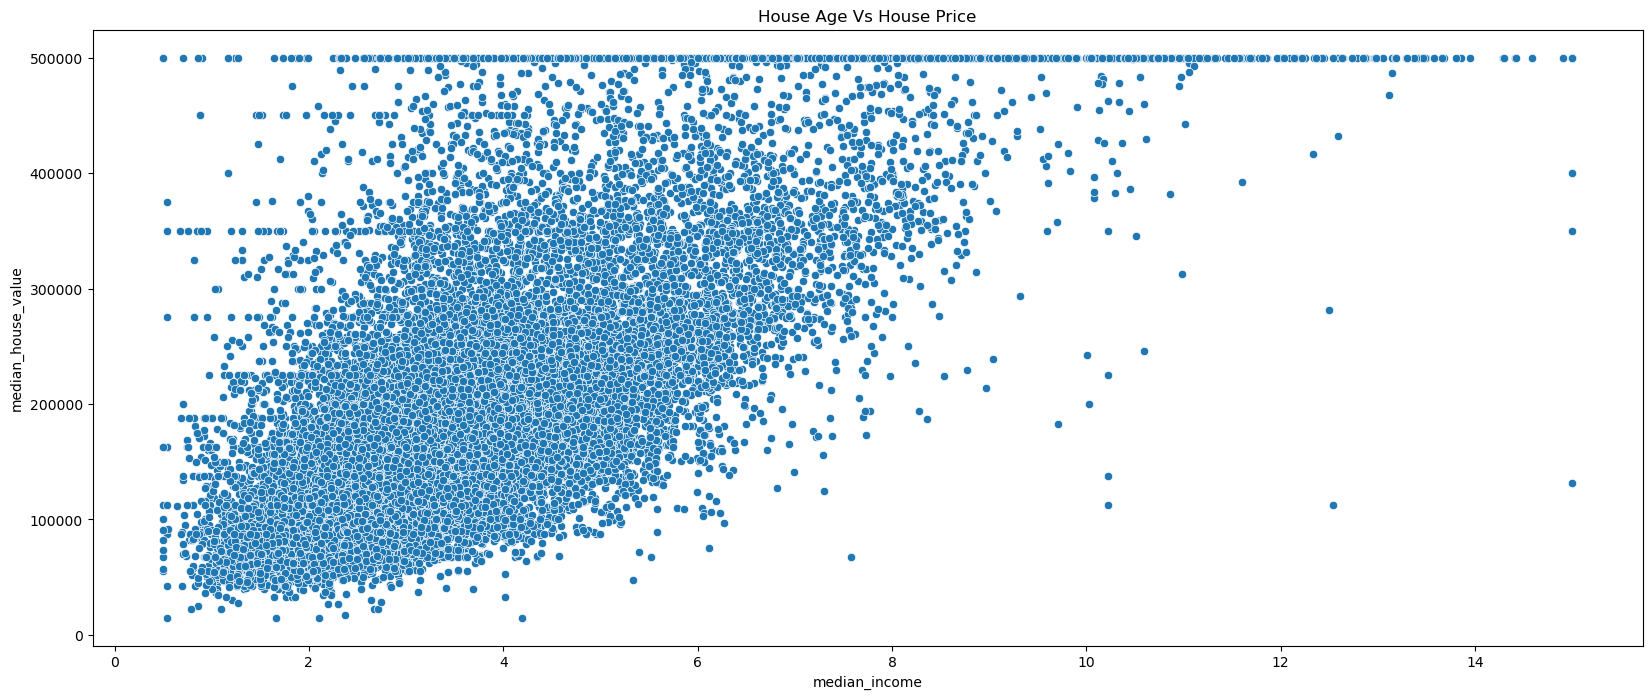

In [148]:
plt.figure(figsize= (20,8))

sns.scatterplot(data=df,
                x='median_income',
                y='median_house_value'
)

plt.title('House Age Vs House Price')
plt.show()

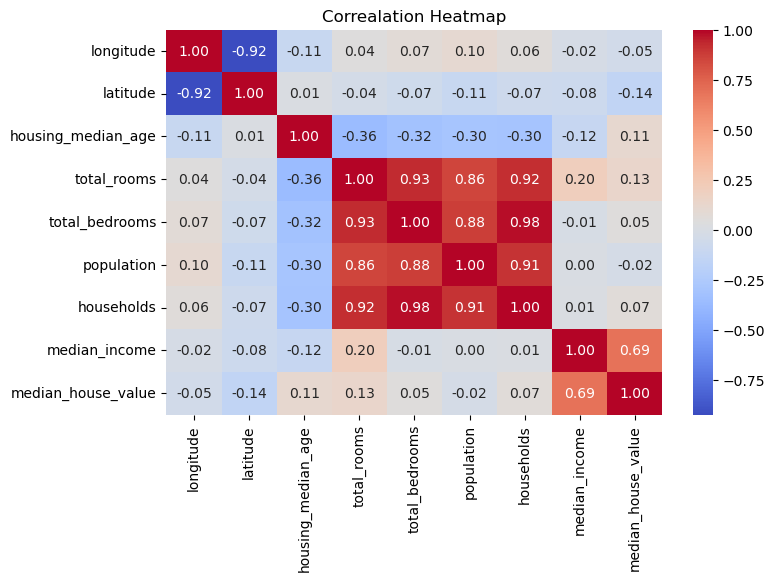

In [149]:
# Correlation Analysis

plt.figure(figsize=(8,5))

sns.heatmap(

df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correalation Heatmap')
plt.show()

# Data Preprocessing

In [150]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [151]:
df['total_bedrooms'].isnull().sum()

np.int64(207)

In [152]:
df['total_bedrooms'] = df['total_bedrooms'].fillna(df['total_bedrooms'].median())

In [153]:
df.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

In [154]:
# Categorical Encoding

df = pd.get_dummies(df,columns = ['ocean_proximity'],drop_first = True,dtype = int)

In [155]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,0,0,1,0


In [156]:
# Separating features and target

X = df.drop(columns = 'median_house_value', axis = 1)
y = df['median_house_value']

In [157]:
# splitting data into train test and split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42)

In [158]:
# Feature scaling

from sklearn.preprocessing import StandardScaler

scaler =  StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [159]:
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(16512, 12)
(4128, 12)


In [160]:
# Model Training
# Linear Regression
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_scaled, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [161]:
y_pred = model.predict(X_test_scaled)

In [162]:
# Actual value Vs Predicted value

comparison = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': y_pred

})

comparison.head()

,Actual Price,Predicted Price
20046,47700.0,54055.448899
3024,45800.0,124225.338937
15663,500001.0,255489.379492
20484,218600.0,268002.431569
9814,278000.0,262769.434816


In [163]:
# Evaluation metrics

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2 )


MAE: 50670.7382409719
MSE: 4908476721.156616
RMSE: 70060.52184473518
R2 Score: 0.6254240620553606


In [164]:
Linear Regression – Model Evaluation

The Linear Regression model was evaluated using MAE, MSE, RMSE, and R² Score.

Evaluation Results:

- MAE: 50,670.74
- MSE: 4,908,476,721.16
- RMSE: 70,060.52
- R² Score: 0.6254

Observations:

1. The model achieved an R² score of approximately 62.54%.
2. The average absolute prediction error is approximately $50,671.
3. The RMSE indicates that larger prediction errors are present.
4. Linear Regression provides a baseline for comparison with other regression algorithms.

Conclusion: Linear Regression captures some relationships in the housing data, but its predictive performance can be further evaluated against more advanced regression models.

SyntaxError: invalid character '–' (U+2013) (3782490582.py, line 1)

In [ ]:
# Actual Vs Predicted Graph

plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel('Actual House Price')
plt.ylabel('Predicted House Price')
plt.title('Actual vs Predicted House Prices')

plt.show()


In [ ]:
Actual vs Predicted House Prices – Observations

1. Many predictions are relatively close to the ideal prediction line.
2. The model shows considerable prediction errors for some observations.
3. Predictions for higher-value houses show greater variation.
4. Some negative predictions are observed for lower-value houses, which are not realistic.

Conclusion: The Linear Regression model captures the general relationship between input features and house prices, but its predictions still have noticeable errors. Other regression algorithms will be tested to improve predictive performance.

In [ ]:
# Decision Tree Regressor

from sklearn.tree import DecisionTreeRegressor

dt_model =  DecisionTreeRegressor(random_state = 42)
dt_model.fit(X_train, y_train)


In [ ]:
dt_pred = dt_model.predict(X_test)

In [ ]:
dt_mae = mean_absolute_error(y_test, dt_pred)

dt_mse = mean_squared_error(y_test, dt_pred)

dt_rmse = np.sqrt(dt_mse)

dt_r2 = r2_score(y_test, dt_pred)

print(" Decision Tree MAE:", dt_mae)
print(" Decision Tree MSE:", dt_mse)
print(" Decision Tree RMSE:", dt_rmse)
print(" Decision Tree R2 Score:", dt_r2 )


In [ ]:
# Model comparison
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree'],
    'MAE': [mae, dt_mae],
    'MSE': [mse, dt_mse],
    'RMSE': [rmse, dt_rmse],
    'R2 Score': [r2, dt_r2]
})

comparison

In [ ]:
# RandomForest Regressor 

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators = 100,
    random_state = 42
)

In [ ]:
rf_model.fit(X_train, y_train)

In [ ]:
rf_pred = rf_model.predict(X_test)

In [ ]:
rf_mae = mean_absolute_error(y_test, rf_pred)

rf_mse = mean_squared_error(y_test, rf_pred)

rf_rmse = np.sqrt(rf_mse)

rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest MAE:", rf_mae)
print("Random Forest MSE:", rf_mse)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R2:", rf_r2)

In [ ]:
# comparison

comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'MAE': [mae, dt_mae, rf_mae],
    'MSE': [mse, dt_mse, rf_mse],
    'RMSE': [rmse, dt_rmse, rf_rmse],
    'R2 Score': [r2, dt_r2, rf_r2]
})

comparison

In [ ]:
# Gradient Boosting

from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators = 100,
    learning_rate = 0.1,
    random_state = 42
)



In [ ]:
gb_model.fit(X_train, y_train)

In [ ]:
gb_pred = gb_model.predict(X_test)

In [ ]:
gb_mae = mean_absolute_error(y_test, rf_pred)

gb_mse = mean_squared_error(y_test, rf_pred)

gb_rmse = np.sqrt(rf_mse)

gb_r2 = r2_score(y_test, rf_pred)

print("Gradient Boosting MAE:", rf_mae)
print("Gradient Boosting MSE:", rf_mse)
print("Gradient Boosting  RMSE:", rf_rmse)
print("Gradient Boosting  R2:", rf_r2)

In [ ]:
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree','Random Forest', 'Gradient Boosting'],
    'MAE': [mae, dt_mae,rf_mae, gb_mae],
    'MSE': [mse, dt_mse, rf_mse, gb_mse],
    'RMSE': [rmse, dt_rmse, rf_rmse, gb_rmse],
    'R2 Score': [r2, dt_r2, rf_r2, gb_r2]
})

comparison

In [165]:
# Model performance comparsion
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

models = {
    'Linear Regression': y_pred,
    'Decision Tree': dt_pred,
    'Random Forest': rf_pred,
    'Gradient Boosting': gb_pred
}

results = []

for name, predictions in models.items():
    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

comparison = pd.DataFrame(results)
comparison

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,50670.738241,4.908477e+09,70060.521845,0.625424
1,Decision Tree,44180.854409,4.865869e+09,69755.779954,0.628676
2,Random Forest,31639.373406,2.404746e+09,49038.209338,0.816489
3,Gradient Boosting,38248.031950,3.123095e+09,55884.659003,0.761670
